# Fase 1 — Análisis exploratorio reproducible: Titanic
**MCDI503 · Exploración Inteligente para la Ciencia de Datos · UNAB**  
**Integrantes:** Verónica Durán Cisterna, Raúl Moya Arriagada, Daniela Rojas Vilches y Manuel Sánchez Cárcamo  
**Dataset:** `datos/titanic.csv`  
**Entrega:** Fase 1 — Sumativa 1 (noviembre de 2026)  
**Propósito:** diagnóstico y exploración inicial; no se entrenan modelos predictivos.

> Fuente exacta, URL y licencia del CSV: **pendiente de confirmar con el material de origen**. El archivo usado para reproducir el análisis se conserva sin alteraciones.

## I. Identificación del proyecto
**Tema:** supervivencia de pasajeros del Titanic. **Unidad de análisis:** fila del archivo de pasajeros; no existe un identificador único de persona en esta versión. **Variable objetivo:** `survived` (0 = no sobrevivió; 1 = sobrevivió). **Variables explicativas exploradas:** `sex`, `pclass`, `age`, `fare`, `sibsp` y `parch`.

Se conserva el archivo original sin modificaciones; las transformaciones se realizan sobre una copia en memoria.

## II. Contexto, objetivo y preguntas exploratorias
El dataset permite estudiar cómo se distribuye la supervivencia entre grupos de pasajeros. El propósito es **describir patrones, identificar problemas de calidad y documentar decisiones reproducibles**, no explicar causalmente el desenlace.

**Preguntas:** (1) ¿Cuál es la tasa global de supervivencia? (2) ¿Cómo cambia por sexo y clase? (3) ¿Qué diferencias presentan edad y tarifa entre sobrevivientes y no sobrevivientes? (4) ¿Qué restricciones de calidad condicionan estas comparaciones?

**Alcance:** revisión estructural, estadística descriptiva, visualización univariada y bivariada, variable derivada y análisis de limitaciones. No se realizan pruebas de hipótesis ni predicciones.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
print('pandas:', pd.__version__)
import sys
print('Python:', sys.version.split()[0])
print('numpy:', np.__version__, '| matplotlib:', __import__('matplotlib').__version__, '| seaborn:', sns.__version__)

pandas: 3.1.1
Python: 3.13.17
numpy: 2.5.4 | matplotlib: 3.11.2 | seaborn: 0.13.2


## III. Carga y revisión inicial
La ruta se resuelve desde la raíz del repositorio o desde la carpeta F1. No se modifican los datos originales.

In [2]:
candidatas = [Path('datos/titanic.csv'), Path('../datos/titanic.csv')]
ruta = next((p for p in candidatas if p.exists()), None)
if ruta is None:
    raise FileNotFoundError('Guarda el archivo original como datos/titanic.csv')
df = pd.read_csv(ruta)
print('Dimensiones:', df.shape)
display(df.head())
df.info()

Dimensiones: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [3]:
display(pd.DataFrame({'tipo': df.dtypes.astype(str), 'nulos': df.isna().sum(), 'porcentaje_nulos': (df.isna().mean()*100).round(2)}))
print('Filas idénticas:', df.duplicated().sum())
print('Columnas:', list(df.columns))

,tipo,nulos,porcentaje_nulos
survived,int64,0,0.00
pclass,int64,0,0.00
sex,str,0,0.00
age,float64,177,19.87
sibsp,int64,0,0.00
parch,int64,0,0.00
fare,float64,0,0.00
embarked,str,2,0.22
class,str,0,0.00
who,str,0,0.00


Filas idénticas: 107
Columnas: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


**Decisión inicial:** no eliminar automáticamente filas con valores idénticos: no existe un identificador único y dos pasajeros podrían compartir todos los atributos disponibles. El conteo de filas idénticas es una señal para revisar, no una prueba de duplicación de personas.

## IV. Exploración preliminar
**Secuencia de trabajo:** describir la calidad y las distribuciones antes de interpretar relaciones. Se presentan cantidades y tasas; las tasas de supervivencia son promedios de la variable binaria `survived`. Los gráficos representan asociaciones descriptivas.

In [4]:
requeridas = {'survived', 'sex', 'pclass', 'age', 'fare'}
faltantes = requeridas - set(df.columns)
if faltantes:
    raise ValueError(f'Faltan columnas requeridas: {faltantes}')
display(df[['age', 'fare']].describe())
display(df['survived'].value_counts(dropna=False).rename('pasajeros'))

,age,fare
count,714.000000,891.000000
mean,29.699118,32.204208
std,14.526497,49.693429
min,0.420000,0.000000
25%,20.125000,7.910400
50%,28.000000,14.454200
75%,38.000000,31.000000
max,80.000000,512.329200


survived
0    549
1    342
Name: pasajeros, dtype: int64

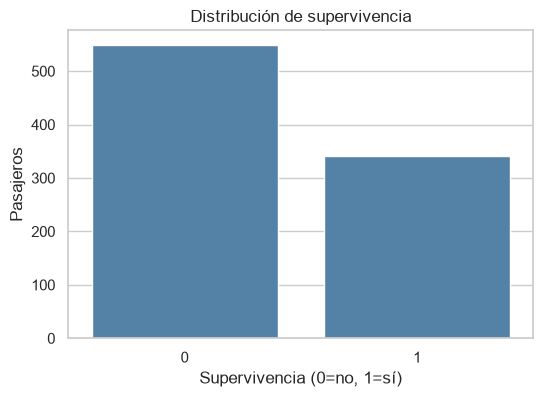

In [5]:
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(data=df, x='survived', ax=ax, color='steelblue')
ax.set(title='Distribución de supervivencia', xlabel='Supervivencia (0=no, 1=sí)', ylabel='Pasajeros')
plt.show()

In [6]:
por_sexo = df.groupby('sex', dropna=False)['survived'].agg(['count','mean'])
por_clase = df.groupby('pclass', dropna=False)['survived'].agg(['count','mean'])
display(por_sexo.rename(columns={'mean':'proporcion_supervivencia'}))
display(por_clase.rename(columns={'mean':'proporcion_supervivencia'}))

,count,proporcion_supervivencia
sex,,
female,314,0.742038
male,577,0.188908


,count,proporcion_supervivencia
pclass,,
1,216,0.629630
2,184,0.472826
3,491,0.242363


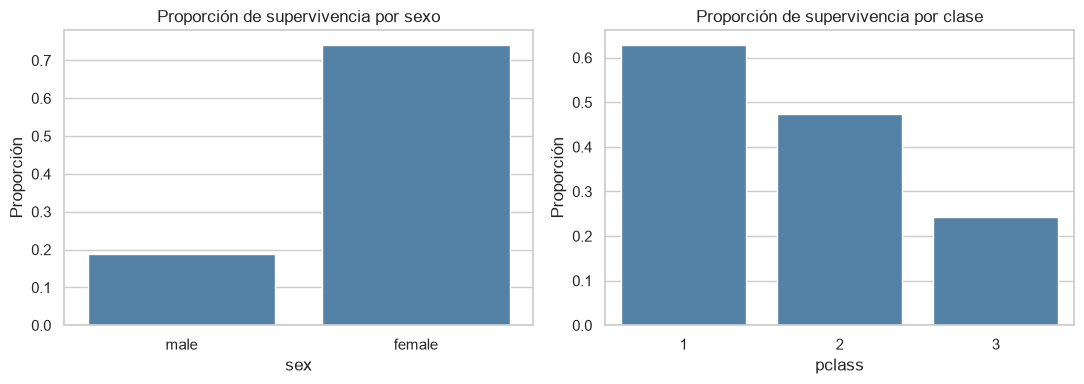

In [7]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
sns.barplot(data=df, x='sex', y='survived', errorbar=None, ax=axes[0], color='steelblue')
sns.barplot(data=df, x='pclass', y='survived', errorbar=None, ax=axes[1], color='steelblue')
axes[0].set(title='Proporción de supervivencia por sexo', ylabel='Proporción')
axes[1].set(title='Proporción de supervivencia por clase', ylabel='Proporción')
plt.tight_layout()
plt.show()

### IV.3 Profundización: sexo × clase y distribuciones de edad/tarifa
**Pregunta:** ¿se mantienen las diferencias por sexo al observar cada clase? Se incluyen tamaños de grupo para evitar sobreinterpretar porcentajes. Se examinan las distribuciones de edad y tarifa, incluyendo su asimetría y posibles valores extremos.

pasajeros  sobrevivientes   tasa
sex    pclass                                  
female 1              94              91  0.968
       2              76              70  0.921
       3             144              72  0.500
male   1             122              45  0.369
       2             108              17  0.157
       3             347              47  0.135

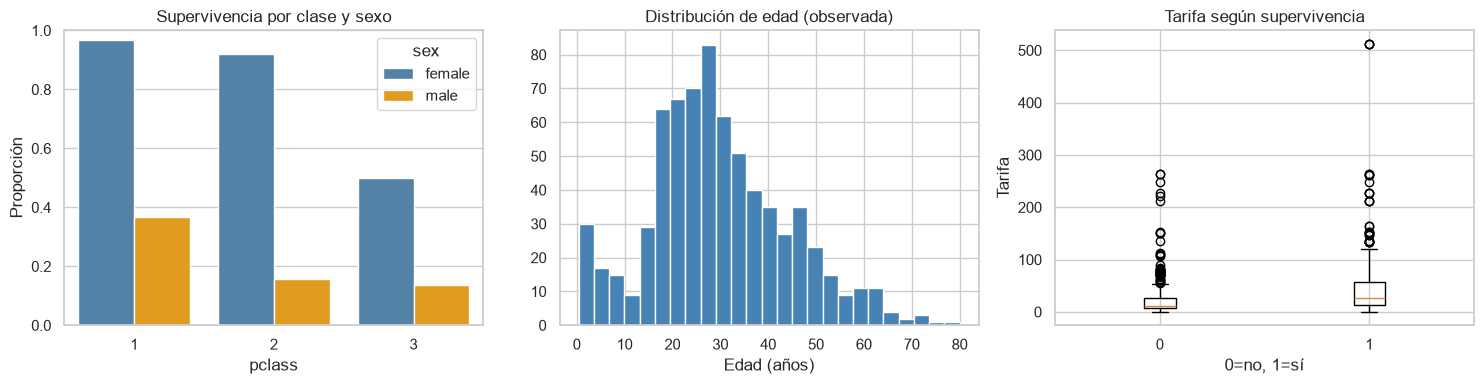

In [8]:
cruce = df.groupby(['sex','pclass'])['survived'].agg(pasajeros='size', sobrevivientes='sum', tasa='mean').round(3)
display(cruce)
fig, axes = plt.subplots(1,3,figsize=(15,4))
sns.barplot(data=df,x='pclass',y='survived',hue='sex',errorbar=None,ax=axes[0],palette=['steelblue','orange'])
axes[0].set(title='Supervivencia por clase y sexo',ylabel='Proporción',ylim=(0,1))
axes[1].hist(df['age'].dropna(),bins=25,color='steelblue')
axes[1].set(title='Distribución de edad (observada)',xlabel='Edad (años)')
axes[2].boxplot([df.loc[df['survived']==0,'fare'].dropna(),df.loc[df['survived']==1,'fare'].dropna()],tick_labels=['0','1'])
axes[2].set(title='Tarifa según supervivencia',xlabel='0=no, 1=sí',ylabel='Tarifa')
plt.tight_layout()
plt.show()

## V. Decisiones y transformaciones iniciales
Se crea una copia de trabajo para no alterar el CSV original. Se deriva `tamano_grupo_familiar = sibsp + parch + 1`: aproxima la cantidad de personas relacionadas registradas, pero **no equivale necesariamente al grupo completo de viaje**.

| Decisión | Motivo | Resultado / efecto |
|---|---|---|
| Mantener las 107 filas idénticas | No hay identificador único; podrían ser pasajeros diferentes | Se conservan 891 registros |
| No imputar las 177 edades ausentes (19,87 %) | Evitar modificar la distribución sin estudiar el mecanismo de ausencia | Las estadísticas de edad utilizan casos disponibles |
| No usar `deck` en las comparaciones principales | Tiene 688 valores faltantes (77,22 %) | Se evita interpretar una variable con cobertura muy limitada |
| No eliminar `alive` ni `class` del CSV | Mantener trazabilidad del origen | Se priorizan `survived` y `pclass` en el análisis para evitar redundancia |
| Crear copia `trabajo` | Proteger el archivo fuente | Transformación reversible y reproducible |

In [9]:
trabajo = df.copy()
if {'sibsp','parch'}.issubset(trabajo.columns):
    trabajo['tamano_grupo_familiar'] = trabajo['sibsp'] + trabajo['parch'] + 1
    display(trabajo['tamano_grupo_familiar'].describe())
print('Registros conservados:', len(trabajo))

count    891.000000
mean       1.904602
std        1.613459
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       11.000000
Name: tamano_grupo_familiar, dtype: float64

Registros conservados: 891


**Registro de decisiones y resultados intermedios:** la lectura de `datos/titanic.csv` arroja 891 filas y 15 columnas. La revisión de nulos muestra 177 edades ausentes, 688 cubiertas (`deck`) ausentes y 2 registros sin puerto de embarque (`embarked`). Se identifican 107 filas idénticas, que **no** se eliminan. La transformación del tamaño familiar conserva los 891 registros. Todas estas decisiones son explícitas para permitir su revisión en fases posteriores.

## VI. Resultados e interpretación inicial
Las salidas previas permiten responder las preguntas planteadas:

1. **Supervivencia global:** sobrevivieron 342 de 891 pasajeros (38,4 %).
2. **Sexo:** la tasa fue aproximadamente **74,2 % en mujeres** y **18,9 % en hombres**. La diferencia es descriptiva y no demuestra por sí sola una causa.
3. **Clase:** sobrevivió aproximadamente **63,0 % en primera**, **47,3 % en segunda** y **24,2 % en tercera**. Las tasas se calcularon dentro de cada clase, no sobre el total general.
4. **Edad y tarifa:** la mediana de edad fue **28 años** en ambos grupos, pero la comparación excluye edades faltantes. La mediana de tarifa fue **26,0** entre sobrevivientes y **10,5** entre no sobrevivientes. La tarifa puede relacionarse con la clase, por lo que no debe interpretarse como factor causal aislado.

**Evidencia reproducible:** las tablas y gráficos de la sección IV sustentan las tasas; la tabla de la celda siguiente sustenta las comparaciones de edad y tarifa. Las diferencias describen únicamente los registros de este CSV.

In [10]:
display(df.groupby('survived')[['age','fare']].agg(['count','median','mean']).round(2))

age                fare              
         count median   mean count median   mean
survived                                        
0          424   28.0  30.63   549   10.5  22.12
1          290   28.0  28.34   342   26.0  48.40

## VII. Supuestos, limitaciones y reproducibilidad
- **Representatividad:** se describen registros de este archivo; no se generaliza a otros conjuntos sin verificar su procedencia.
- **Identificación:** sin ID único, las 107 filas idénticas no se pueden clasificar con seguridad como errores.
- **Datos ausentes:** `age` tiene 177 valores faltantes y `deck` 688; los resultados que dependen de ellas tienen cobertura desigual.
- **Variables redundantes:** `alive` puede repetir la información de `survived`; `class`, la de `pclass`. Se prioriza una codificación por concepto.
- **Asociación, no causalidad:** sexo, clase y tarifa pueden estar relacionados entre sí; este EDA no controla confusión.
- **Trazabilidad:** ejecutar las celdas de arriba abajo, con `datos/titanic.csv` en la raíz del repositorio, utilizando las bibliotecas del archivo `requirements.txt`.

**Reproducibilidad:** en VS Code, seleccionar el kernel de Python, instalar dependencias con `python -m pip install -r requirements.txt`, elegir **Restart Kernel and Run All**, comprobar que no aparezcan errores y guardar el notebook con las salidas.

## VIII. Cierre y continuidad
El EDA permitió caracterizar **891 registros y 15 variables**, documentar faltantes y detectar diferencias descriptivas de supervivencia según sexo y clase. También se observaron diferencias en tarifa y una cobertura incompleta de edad. Estos hallazgos son útiles para formular nuevas preguntas, pero no establecen causas.

**Próximos pasos:** (1) evaluar si los nulos en edad siguen patrones por sexo, clase o supervivencia; (2) investigar la utilidad y los sesgos de `deck`; (3) profundizar el análisis conjunto de sexo y clase; (4) revisar distribuciones extremas de tarifa; (5) comparar estrategias de tratamiento de faltantes antes de cualquier modelamiento.

**Control de entrega:** completar y verificar la fuente del dataset; ejecutar **Restart Kernel and Run All**; guardar resultados; verificar consistencia de cifras con el informe PDF (máximo tres páginas); incorporar al PDF al menos tres fuentes pertinentes en APA 7, sin inventar referencias.